# 50 · SAC from scratch on the MuJoCo pendulum, and the sample-efficiency gap vs PPO

In [1]:
import copy, time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.rl_envs import PendulumEnv
from vlacourse.rl_algos import ppo, evaluate_policy
from vlacourse import show_video

torch.set_num_threads(4)

def mlp(i, o, h=256):
    return nn.Sequential(nn.Linear(i, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, o))

class Actor(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.net = mlp(obs_dim, 2 * act_dim)

    def forward(self, obs, deterministic=False):
        mu, log_std = self.net(obs).chunk(2, -1)
        std = log_std.clamp(-5, 2).exp()
        u = mu if deterministic else mu + std * torch.randn_like(mu)
        a = torch.tanh(u)
        logp = torch.distributions.Normal(mu, std).log_prob(u).sum(-1) - (2 * (np.log(2) - u - nn.functional.softplus(-2 * u))).sum(-1)
        return a, logp

class Replay:
    def __init__(self, obs_dim, act_dim, size=200_000):
        self.o, self.a = np.zeros((size, obs_dim), np.float32), np.zeros((size, act_dim), np.float32)
        self.r, self.o2, self.d = np.zeros(size, np.float32), np.zeros((size, obs_dim), np.float32), np.zeros(size, np.float32)
        self.n, self.i, self.size = 0, 0, size

    def add(self, o, a, r, o2, d):
        self.o[self.i], self.a[self.i], self.r[self.i], self.o2[self.i], self.d[self.i] = o, a, r, o2, d
        self.i = (self.i + 1) % self.size; self.n = min(self.n + 1, self.size)

    def sample(self, b):
        idx = np.random.randint(0, self.n, b)
        return [torch.tensor(x[idx]) for x in (self.o, self.a, self.r, self.o2, self.d)]

def sac(env, total_steps=20_000, start=1000, batch=256, gamma=0.99, tau=0.005, lr=3e-4, seed=0, eval_every=1000):
    torch.manual_seed(seed); np.random.seed(seed)
    od, ad = env.observation_space.shape[0], env.action_space.shape[0]
    actor, q1, q2 = Actor(od, ad), mlp(od + ad, 1), mlp(od + ad, 1)
    q1_t, q2_t = copy.deepcopy(q1), copy.deepcopy(q2)
    log_alpha = torch.zeros(1, requires_grad=True); target_ent = -ad
    opt_a, opt_q = torch.optim.Adam(actor.parameters(), lr), torch.optim.Adam(list(q1.parameters()) + list(q2.parameters()), lr)
    opt_al = torch.optim.Adam([log_alpha], lr)
    buf, curve = Replay(od, ad), []
    obs, _ = env.reset(seed=seed)
    for t in range(1, total_steps + 1):
        if t < start:
            a = env.action_space.sample()
        else:
            with torch.no_grad():
                a = actor(torch.tensor(obs))[0].numpy()
        obs2, r, te, tr, _ = env.step(a)
        buf.add(obs, a, r, obs2, float(te)); obs = obs2
        if te or tr:
            obs, _ = env.reset()
        if t >= start:
            o, a_b, r_b, o2, d = buf.sample(batch)
            alpha = log_alpha.exp().detach()
            with torch.no_grad():
                a2, lp2 = actor(o2)
                q_t = torch.min(q1_t(torch.cat([o2, a2], -1)), q2_t(torch.cat([o2, a2], -1))).squeeze(-1)
                y = r_b + gamma * (1 - d) * (q_t - alpha * lp2)
            oa = torch.cat([o, a_b], -1)
            lq = ((q1(oa).squeeze(-1) - y) ** 2).mean() + ((q2(oa).squeeze(-1) - y) ** 2).mean()
            opt_q.zero_grad(); lq.backward(); opt_q.step()
            a_new, lp = actor(o)
            q_new = torch.min(q1(torch.cat([o, a_new], -1)), q2(torch.cat([o, a_new], -1))).squeeze(-1)
            la = (alpha * lp - q_new).mean()
            opt_a.zero_grad(); la.backward(); opt_a.step()
            lal = -(log_alpha * (lp.detach() + target_ent)).mean()
            opt_al.zero_grad(); lal.backward(); opt_al.step()
            with torch.no_grad():
                for net, tgt in [(q1, q1_t), (q2, q2_t)]:
                    for p, pt in zip(net.parameters(), tgt.parameters()):
                        pt.mul_(1 - tau).add_(tau * p)
        if t % eval_every == 0:
            curve.append((t, evaluate_policy(PendulumEnv(), lambda x: actor(torch.tensor(x), deterministic=True)[0].detach().numpy(), 5), log_alpha.exp().item()))
    return actor, curve

In [2]:
t0 = time.time()
actor, sac_curve = sac(PendulumEnv(), total_steps=20_000)
print(f"SAC: final eval return {sac_curve[-1][1]:.0f} after {sac_curve[-1][0]} env steps ({time.time() - t0:.0f}s)")

SAC: final eval return -214 after 20000 env steps (81s)


In [3]:
t0 = time.time()
ac, ppo_log = ppo(PendulumEnv(), discrete=False, total_steps=300_000, n_steps=2048, lr=3e-4, eval_env_fn=PendulumEnv, eval_every=5)
last = [l for l in ppo_log if "eval" in l][-1]
print(f"PPO: final eval return {last['eval']:.0f} after {last['steps']} env steps ({time.time() - t0:.0f}s)")

PPO: final eval return -221 after 296960 env steps (62s)


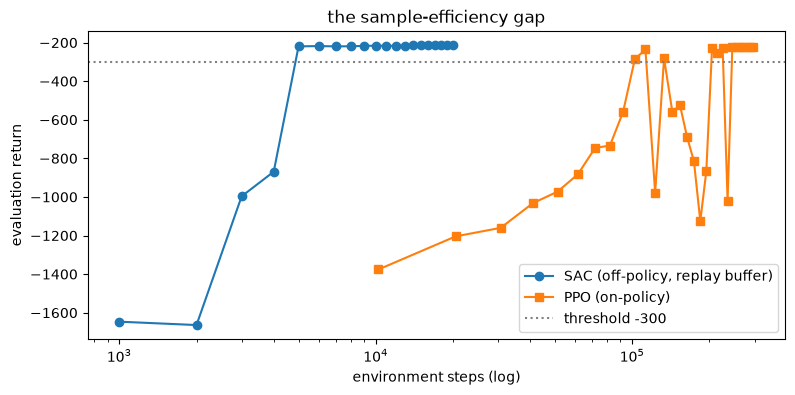

steps to reach -300:  SAC 5000   PPO 102400   ratio 20.5x


In [4]:
plt.figure(figsize=(9, 4))
plt.plot([c[0] for c in sac_curve], [c[1] for c in sac_curve], "o-", label="SAC (off-policy, replay buffer)")
plt.plot([l["steps"] for l in ppo_log if "eval" in l], [l["eval"] for l in ppo_log if "eval" in l], "s-", label="PPO (on-policy)")
plt.xscale("log"); plt.xlabel("environment steps (log)"); plt.ylabel("evaluation return"); plt.axhline(-300, c="gray", ls=":", label="threshold -300")
plt.legend(); plt.title("the sample-efficiency gap"); plt.show()
first = lambda xs: next((s for s, v in xs if v > -300), None)
s_sac = first([(c[0], c[1]) for c in sac_curve]); s_ppo = first([(l["steps"], l["eval"]) for l in ppo_log if "eval" in l])
print(f"steps to reach -300:  SAC {s_sac}   PPO {s_ppo}   ratio {s_ppo / s_sac if s_sac and s_ppo else float('nan'):.1f}x")

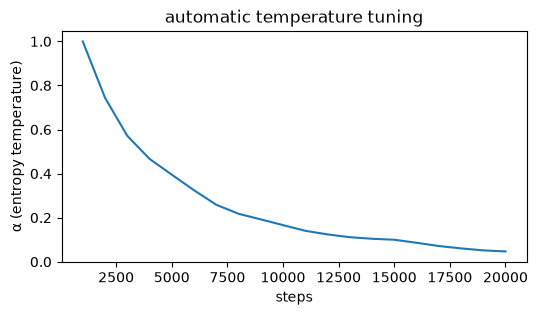

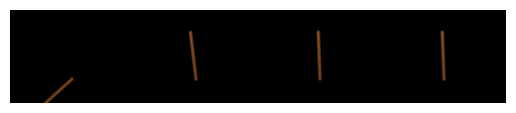

In [5]:
plt.figure(figsize=(6, 3)); plt.plot([c[0] for c in sac_curve], [c[2] for c in sac_curve]); plt.xlabel("steps"); plt.ylabel("α (entropy temperature)")
plt.title("automatic temperature tuning"); plt.show()
env = PendulumEnv(); obs, _ = env.reset(seed=7); frames = []
for t in range(200):
    with torch.no_grad():
        obs, *_ = env.step(actor(torch.tensor(obs), deterministic=True)[0].numpy())
    if t % 2 == 0:
        frames.append(env.render())
show_video(frames, fps=25, title="SAC pendulum swing-up")
plt.imshow(np.hstack(frames[::25][:4])); plt.axis("off"); plt.show()